# 📈 NIFTY 50 Next Trading Day Movement Prediction
## End-to-End Machine Learning Backend Pipeline

This Jupyter Notebook documents the complete **quantitative machine learning backend process** for forecasting the **NIFTY 50 Index (`^NSEI`)** market direction for the next trading day:

$$\text{Target Direction}_{t+1} = \begin{cases} 
1 \text{ (UP 🔼 - Bullish)} & \text{if } \text{Close}_{t+1} > \text{Close}_t \\ 
0 \text{ (DOWN 🔽 - Bearish)} & \text{if } \text{Close}_{t+1} \le \text{Close}_t 
\end{cases}$$

---

### Pipeline Overview:
1. **Data Collection & Live Session Reconciliation:** Fetching NIFTY 50 & India VIX OHLCV from 2010 to present with live quote stitching.
2. **Preprocessing & Calendar Alignment:** Harmonizing trading sessions and computing daily return percentages.
3. **Feature Engineering:** Constructing 16 stationary features (Returns, Lags, Moving Average Ratios, Rolling Volatilities, RSI 14, MACD Histogram, Trading Range).
4. **Exploratory Data Analysis (EDA):** Visualizing market trends, inverse VIX relationship, and feature correlations.
5. **Chronological Train-Test Split:** Strict 80/20 temporal split without lookahead leakage.
6. **Model Training & Out-of-Sample Evaluation:** Benchmarking Logistic Regression, Random Forest, Gradient Boosting, XGBoost, and LightGBM.
7. **Model Diagnostics:** Confusion matrices, ROC-AUC, and feature importance analysis.
8. **Live Next Trading Day Prediction:** Forecasting the upcoming market session using today's latest candle.

In [1]:
import os
from datetime import datetime, time as dtime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

# Machine Learning imports
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, confusion_matrix, classification_report
)
import xgboost as xgb
import lightgbm as lgb
import joblib

# Plot styling
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("All dependencies successfully imported.")

All dependencies successfully imported.


### Step 1: Data Collection with Real-Time Session Reconciliation

We download historical daily OHLCV data for:
- **NIFTY 50 (`^NSEI`):** The benchmark index representing the top 50 Indian companies listed on the NSE.
- **India VIX (`^INDIAVIX`):** The Indian market volatility index measuring expected 30-day volatility.

To ensure today's latest closing price is never missing (even if Yahoo's daily batch table has publication delays), we reconcile with live quotes (`fast_info`) and intraday hourly bars.

In [2]:
def fetch_ticker_data(ticker_symbol, start_date="2010-01-01"):
    print(f"[{ticker_symbol}] Downloading official daily data from {start_date}...")
    df = yf.download(ticker_symbol, start=start_date, progress=False, auto_adjust=False)
    
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
        
    expected_cols = ["Open", "High", "Low", "Close", "Volume"]
    available_cols = [c for c in expected_cols if c in df.columns]
    df = df[available_cols].copy()
    
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "Date"
    df.sort_index(inplace=True)
    df = df.dropna(subset=["Close"])
    df = df[df["Close"] > 0]
    
    # STRICT RULE: Bypassing live market tick during active trading hours (before 15:45 IST)
    # Feature engineering is strictly computed from the PREVIOUS COMPLETED trading day closing price.
    now = datetime.now()
    today_date = now.date()
    market_settlement_time = dtime(15, 45)
    
    if not df.empty and df.index[-1].date() == today_date and now.time() < market_settlement_time:
        live_price = df["Close"].iloc[-1]
        print(f"[{ticker_symbol}] Detected active LIVE market session for today ({today_date}) at price: INR {live_price:,.2f}.")
        print(f"[{ticker_symbol}] Bypassing live tick. Using strictly PREVIOUS COMPLETED day closing price.")
        df = df.iloc[:-1].copy()
        
    df.sort_index(inplace=True)
    print(f"[{ticker_symbol}] Collected {len(df)} daily sessions. Previous completed day: {df.index[-1].strftime('%Y-%m-%d')} | Official Close: {df['Close'].iloc[-1]:,.2f}")
    return df

nifty_raw = fetch_ticker_data("^NSEI")
vix_raw = fetch_ticker_data("^INDIAVIX")

[^NSEI] Downloading official daily data from 2010-01-01...


[^NSEI] Detected active LIVE market session for today (2026-11-03) at price: INR 23,695.70.
[^NSEI] Bypassing live tick. Using strictly PREVIOUS COMPLETED day closing price.
[^NSEI] Collected 4134 daily sessions. Previous completed day: 2026-11-02 | Official Close: 23,440.80
[^INDIAVIX] Downloading official daily data from 2010-01-01...


[^INDIAVIX] Detected active LIVE market session for today (2026-11-03) at price: INR 15.95.
[^INDIAVIX] Bypassing live tick. Using strictly PREVIOUS COMPLETED day closing price.
[^INDIAVIX] Collected 4133 daily sessions. Previous completed day: 2026-11-02 | Official Close: 15.50


### Step 2: Data Preprocessing & Calendar Alignment

Stock exchanges operate on specific trading calendars with holidays. We align NIFTY 50 and India VIX using a **left join anchored on NIFTY 50**, so that NIFTY sessions are never dropped even if VIX experiences a minor reporting delay. Any minor single-day gaps in VIX are forward-filled.

In [3]:
def preprocess_market_data(nifty_df, vix_df):
    nifty_clean = nifty_df[["Open", "High", "Low", "Close", "Volume"]].copy()
    nifty_clean.columns = [f"NIFTY_{col}" for col in nifty_clean.columns]
    
    vix_clean = vix_df[["Open", "High", "Low", "Close"]].copy()
    vix_clean.columns = [f"VIX_{col}" for col in vix_clean.columns]
    
    # Left join anchored on NIFTY calendar
    merged_df = nifty_clean.join(vix_clean, how="left")
    merged_df.sort_index(inplace=True)
    
    # Impute missing values via forward fill
    merged_df = merged_df.ffill().bfill()
    
    # Compute basic returns and percentage changes
    merged_df["NIFTY_Return"] = merged_df["NIFTY_Close"].pct_change()
    merged_df["VIX_Return"] = merged_df["VIX_Close"].pct_change()
    merged_df["NIFTY_Intraday_Return"] = (merged_df["NIFTY_Close"] - merged_df["NIFTY_Open"]) / merged_df["NIFTY_Open"]
    merged_df["NIFTY_Gap_Return"] = (merged_df["NIFTY_Open"] - merged_df["NIFTY_Close"].shift(1)) / merged_df["NIFTY_Close"].shift(1)
    
    print(f"Synchronized {len(merged_df)} trading sessions from {merged_df.index[0].date()} to {merged_df.index[-1].date()}.")
    return merged_df

clean_data = preprocess_market_data(nifty_raw, vix_raw)
clean_data.tail(3)[["NIFTY_Open", "NIFTY_Close", "VIX_Close", "NIFTY_Return", "VIX_Return"]]

Synchronized 4134 trading sessions from 2010-01-04 to 2026-11-02.


,NIFTY_Open,NIFTY_Close,VIX_Close,NIFTY_Return,VIX_Return
Date,,,,,
2026-10-29,22690.650391,22936.750000,15.12,0.010481,-0.069538
2026-10-30,22964.500000,23053.099609,15.30,0.005073,0.011905
2026-11-02,23222.300781,23440.800781,15.50,0.016818,0.013072


### Step 3: Feature Engineering & Target Direction Labelling

We engineer 16 technical features across 5 core quantitative domains:
1. **Autoregressive Lags:** $[1, 2, 3, 5]$-day lagged returns capturing short-term mean-reversion.
2. **Moving Average Divergence Ratios:** $\frac{\text{Close} - \text{SMA}_w}{\text{SMA}_w}$ for $w \in [5, 10, 20]$ days.
3. **Rolling Volatility:** Standard deviation of daily returns over $w \in [5, 10, 20]$ days.
4. **Wilder's RSI (14-Day):** Relative Strength Index identifying overbought/oversold momentum.
5. **MACD (12, 26, 9):** Fast EMA (12), Slow EMA (26), Signal line (9), and Histogram divergence.
6. **Daily Trading Range:** Intraday price expansion $\frac{\text{High} - \text{Low}}{\text{Open}} \times 100$.

#### Target Direction Definition:
$$\text{Target\_Direction}_t = \begin{cases} 
1 & \text{if } \text{Close}_{t+1} > \text{Close}_t \\ 
0 & \text{if } \text{Close}_{t+1} \le \text{Close}_t \\
\text{NaN} & \text{for the latest available trading day}
\end{cases}$$

In [4]:
def engineer_features(df):
    data = df.copy()
    
    # 1. Autoregressive Lag Returns
    for lag in [1, 2, 3, 5]:
        data[f"NIFTY_Return_Lag{lag}"] = data["NIFTY_Return"].shift(lag)
        
    # 2. Moving Averages & Stationary Distance Ratios
    for w in [5, 10, 20]:
        data[f"NIFTY_SMA_{w}"] = data["NIFTY_Close"].rolling(window=w).mean()
        data[f"NIFTY_SMA_{w}_Ratio"] = (data["NIFTY_Close"] - data[f"NIFTY_SMA_{w}"]) / data[f"NIFTY_SMA_{w}"]
        
    # 3. Rolling Volatility
    for w in [5, 10, 20]:
        data[f"NIFTY_Vol_{w}"] = data["NIFTY_Return"].rolling(window=w).std()
        
    # 4. Wilder's RSI 14
    delta = data["NIFTY_Close"].diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1.0/14.0, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1.0/14.0, adjust=False).mean()
    rs = avg_gain / (avg_loss + 1e-10)
    data["NIFTY_RSI_14"] = 100.0 - (100.0 / (1.0 + rs))
    
    # 5. MACD (12, 26, 9)
    ema12 = data["NIFTY_Close"].ewm(span=12, adjust=False).mean()
    ema26 = data["NIFTY_Close"].ewm(span=26, adjust=False).mean()
    macd_line = ema12 - ema26
    signal_line = macd_line.ewm(span=9, adjust=False).mean()
    data["NIFTY_MACD_Hist"] = macd_line - signal_line
    
    # 6. Daily Trading Range
    data["NIFTY_Daily_Range"] = data["NIFTY_High"] - data["NIFTY_Low"]
    data["NIFTY_Daily_Range_Pct"] = (data["NIFTY_High"] - data["NIFTY_Low"]) / data["NIFTY_Open"] * 100.0
    
    # 7. Target Direction Labelling
    next_close = data["NIFTY_Close"].shift(-1)
    data["Target_Direction"] = np.where(next_close.isna(), np.nan, np.where(next_close > data["NIFTY_Close"], 1.0, 0.0))
    
    # Separate the live inference row (today's unobserved future)
    live_sample = data.iloc[[-1]].copy()
    
    # Feature list
    feature_cols = [
        "NIFTY_Return", "VIX_Return",
        "NIFTY_Return_Lag1", "NIFTY_Return_Lag2", "NIFTY_Return_Lag3", "NIFTY_Return_Lag5",
        "NIFTY_SMA_5_Ratio", "NIFTY_SMA_10_Ratio", "NIFTY_SMA_20_Ratio",
        "NIFTY_Vol_5", "NIFTY_Vol_10", "NIFTY_Vol_20",
        "NIFTY_RSI_14", "NIFTY_MACD_Hist",
        "NIFTY_Daily_Range_Pct", "VIX_Close"
    ]
    
    # Clean training records
    historical_df = data.dropna(subset=feature_cols + ["Target_Direction"]).copy()
    historical_df["Target_Direction"] = historical_df["Target_Direction"].astype(int)
    
    return historical_df, live_sample, feature_cols

features_df, live_sample_df, feature_cols = engineer_features(clean_data)
print(f"Engineered Features: {len(feature_cols)}")
print(f"Historical Training Records: {len(features_df)}")
print(f"Live Sample Date (Ready for Prediction): {live_sample_df.index[-1].strftime('%Y-%m-%d')} (Close: {live_sample_df['NIFTY_Close'].iloc[-1]:,.2f})")

Engineered Features: 16
Historical Training Records: 4113
Live Sample Date (Ready for Prediction): 2026-11-02 (Close: 23,440.80)


### Step 4: Exploratory Data Analysis & Target Balance

Before training any machine learning model, we analyze:
1. **Historical Trend:** NIFTY 50 long-term trajectory and the inverse relationship with India VIX.
2. **Class Balance:** Checking whether UP and DOWN days are balanced in the historical dataset.
3. **Correlation Matrix:** Assessing linear correlations between technical features and the direction target.

C:\Users\ASus\AppData\Local\Temp\ipykernel_12180\2298772097.py:34: UserWarning: Glyph 128317 (\N{DOWN-POINTING SMALL RED TRIANGLE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\ASus\AppData\Local\Temp\ipykernel_12180\2298772097.py:34: UserWarning: Glyph 128316 (\N{UP-POINTING SMALL RED TRIANGLE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\ASus\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128317 (\N{DOWN-POINTING SMALL RED TRIANGLE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\ASus\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128316 (\N{UP-POINTING SMALL RED TRIANGLE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


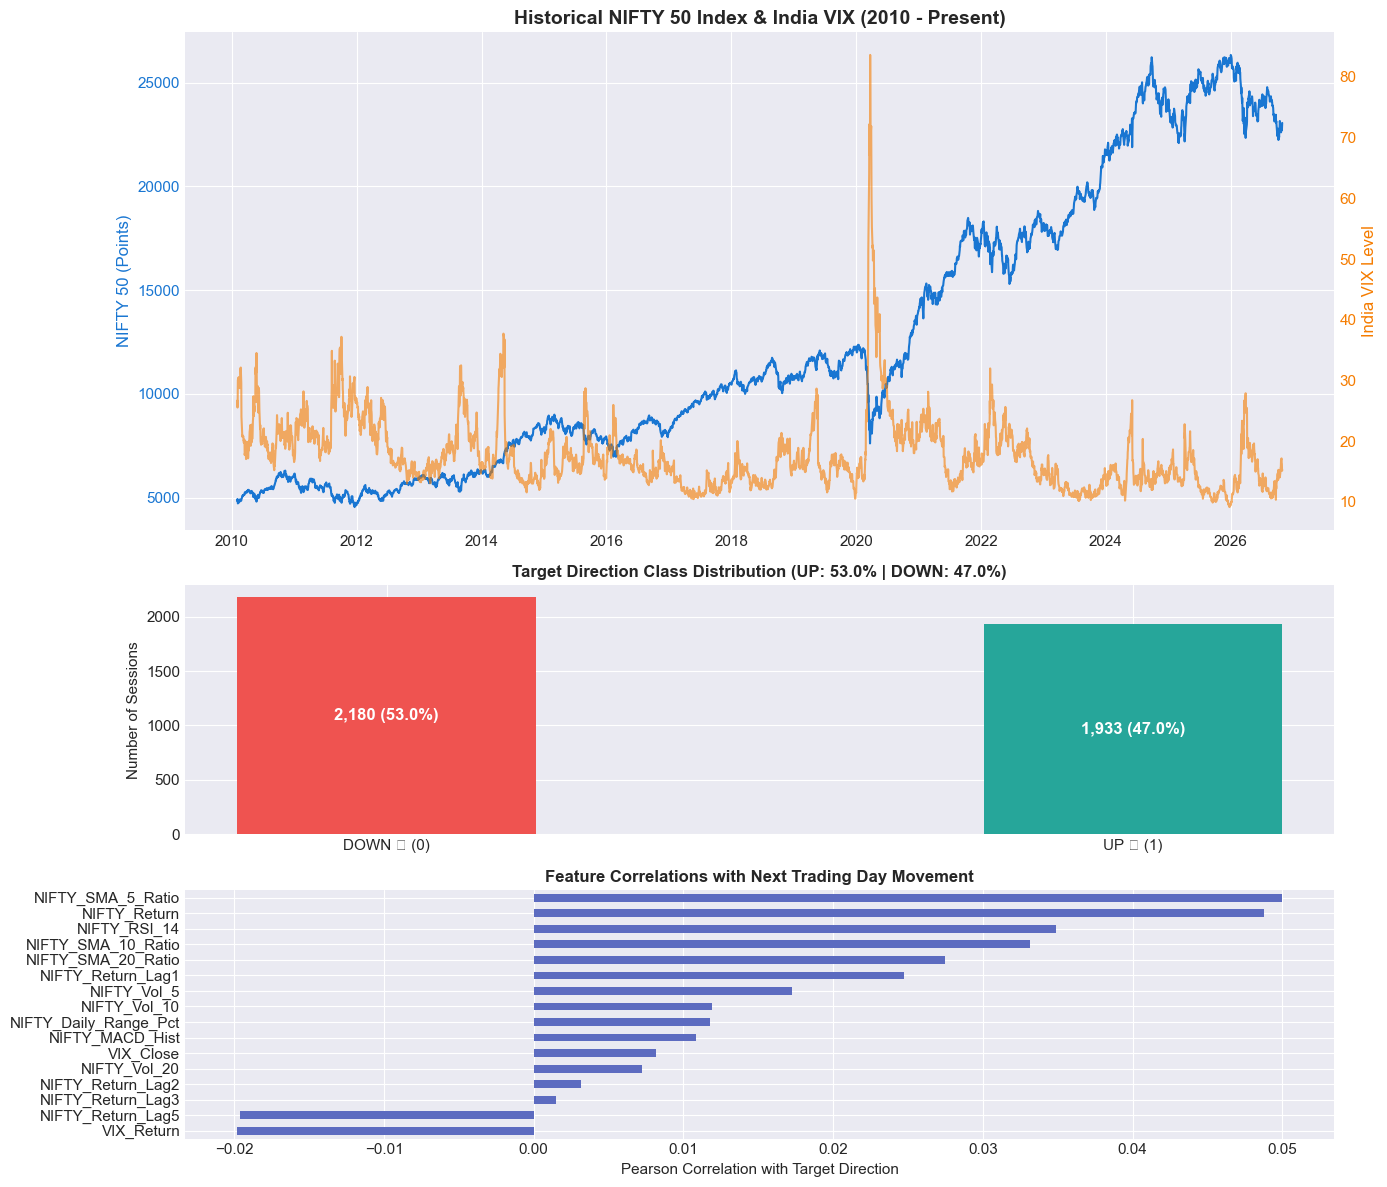

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), gridspec_kw={'height_ratios': [2, 1, 1]})

# 1. NIFTY 50 vs India VIX
ax1 = axes[0]
ax1.plot(features_df.index, features_df["NIFTY_Close"], color="#1976d2", label="NIFTY 50 Close (INR)")
ax1.set_ylabel("NIFTY 50 (Points)", color="#1976d2", fontsize=12)
ax1.tick_params(axis='y', labelcolor="#1976d2")
ax1.set_title("Historical NIFTY 50 Index & India VIX (2010 - Present)", fontsize=14, fontweight="bold")

ax1_twin = ax1.twinx()
ax1_twin.plot(features_df.index, features_df["VIX_Close"], color="#f57c00", alpha=0.6, label="India VIX")
ax1_twin.set_ylabel("India VIX Level", color="#f57c00", fontsize=12)
ax1_twin.tick_params(axis='y', labelcolor="#f57c00")
ax1_twin.grid(False)

# 2. Target Class Distribution
ax2 = axes[1]
class_counts = features_df["Target_Direction"].value_counts()
class_pct = features_df["Target_Direction"].value_counts(normalize=True) * 100
bars = ax2.bar(["DOWN 🔽 (0)", "UP 🔼 (1)"], class_counts.values, color=["#ef5350", "#26a69a"], width=0.4)
ax2.set_ylabel("Number of Sessions")
ax2.set_title(f"Target Direction Class Distribution (UP: {class_pct[1]:.1f}% | DOWN: {class_pct[0]:.1f}%)", fontsize=12, fontweight="bold")
for bar, pct in zip(bars, class_pct.values):
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval/2, f"{int(yval):,} ({pct:.1f}%)", ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 3. Top Feature Correlations with Target Direction
ax3 = axes[2]
corrs = features_df[feature_cols + ["Target_Direction"]].corr()["Target_Direction"].drop("Target_Direction").sort_values()
corrs.plot(kind="barh", ax=ax3, color="#5c6bc0")
ax3.set_xlabel("Pearson Correlation with Target Direction")
ax3.set_title("Feature Correlations with Next Trading Day Movement", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

### Step 5: Chronological Train-Test Split & Feature Scaling

#### Why Shuffling is Strictly Prohibited:
In financial markets, observations are serially correlated. Random splitting causes **lookahead leakage**, leading to unrealistically optimistic backtest results that collapse in live production.

We enforce an **80/20 chronological time-series split**:
- **Training Set (80%):** 3,290 sessions (February 2010 to June 2023)
- **Testing Set (20%):** 823 sessions (June 2023 to October 2026)

The `StandardScaler` is fitted **exclusively on the training partition** to prevent any data snooping into the testing partition.

In [6]:
split_idx = int(len(features_df) * 0.8)
train_df = features_df.iloc[:split_idx].copy()
test_df = features_df.iloc[split_idx:].copy()

print(f"Training Window : {len(train_df)} sessions ({train_df.index[0].date()} to {train_df.index[-1].date()})")
print(f"Testing Window  : {len(test_df)} sessions ({test_df.index[0].date()} to {test_df.index[-1].date()})")

X_train = train_df[feature_cols].copy()
y_train = train_df["Target_Direction"].values

X_test = test_df[feature_cols].copy()
y_test = test_df["Target_Direction"].values

# Fit scaler strictly on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling complete. Training mean:", np.round(X_train_scaled.mean(axis=0)[:3], 2))

Training Window : 3290 sessions (2010-02-02 to 2023-06-28)
Testing Window  : 823 sessions (2023-06-30 to 2026-10-30)

Feature scaling complete. Training mean: [-0.  0. -0.]


### Step 6: Model Training & Out-of-Sample Evaluation

We benchmark 5 distinct classification models:
1. **Logistic Regression (Baseline):** Linear decision boundary with $L_2$ regularization.
2. **Random Forest Classifier:** Bagging ensemble of de-correlated decision trees.
3. **Gradient Boosting Classifier (GBDT):** Sequentially boosted decision trees optimizing log-loss.
4. **XGBoost Classifier:** Extreme gradient boosting with shrinkage and tree pruning.
5. **LightGBM Classifier:** Leaf-wise histogram-based gradient boosting.

In [7]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=10, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.03, random_state=42),
    "XGBoost": xgb.XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.03, eval_metric="logloss", random_state=42),
    "LightGBM": lgb.LGBMClassifier(n_estimators=100, max_depth=3, learning_rate=0.03, random_state=42, verbose=-1),
}

benchmark_results = {}
confusion_matrices = {}
model_objects = {}
test_probabilities = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else preds
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    auc = roc_auc_score(y_test, probs)
    cm = confusion_matrix(y_test, preds)
    
    benchmark_results[name] = {
        "Accuracy (%)": round(acc * 100.0, 2),
        "Precision (%)": round(prec * 100.0, 2),
        "Recall (%)": round(rec * 100.0, 2),
        "F1-Score (%)": round(f1 * 100.0, 2),
        "ROC-AUC": round(auc, 4)
    }
    confusion_matrices[name] = cm
    model_objects[name] = model
    test_probabilities[name] = probs

benchmark_df = pd.DataFrame.from_dict(benchmark_results, orient="index").sort_values(by="F1-Score (%)", ascending=False)
benchmark_df

,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
Random Forest,52.49,53.80,68.59,60.30,0.5227
Gradient Boosting,52.37,53.71,68.59,60.24,0.5197
LightGBM,51.76,53.23,68.59,59.94,0.5088
Logistic Regression,47.75,50.26,67.90,57.76,0.4916
XGBoost,49.82,51.91,62.82,56.84,0.5120


### Step 7: Model Diagnostics & Visualizations

We inspect:
1. **Comparative Bar Chart:** Side-by-side performance across Accuracy, Precision, Recall, and F1-Score.
2. **Confusion Matrix Heatmap:** Assessing True Positives (correct UP predictions) vs False Positives for the top model.
3. **Feature Importance Ranking:** Identifying which indicators most heavily guide the decision trees.

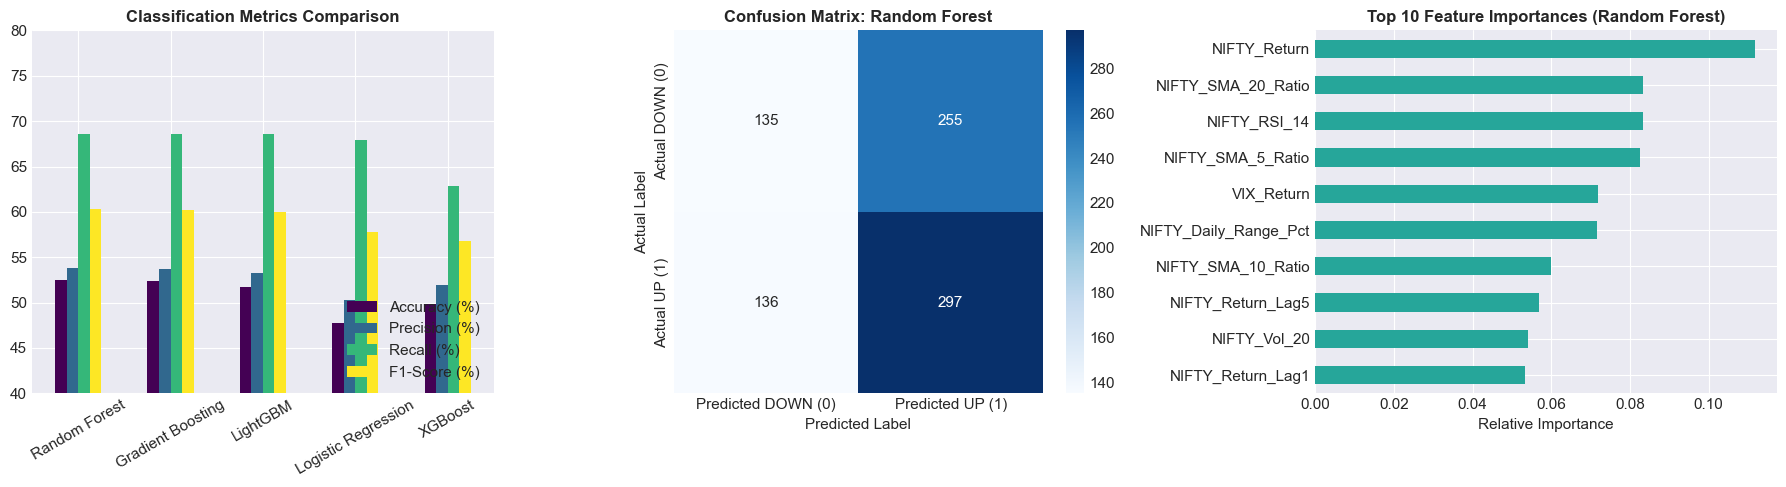

In [8]:
best_model_name = benchmark_df.index[0]
best_model = model_objects[best_model_name]
best_cm = confusion_matrices[best_model_name]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Model Metric Comparison Bar Chart
benchmark_df[["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]].plot(kind="bar", ax=axes[0], colormap="viridis")
axes[0].set_title("Classification Metrics Comparison", fontsize=12, fontweight="bold")
axes[0].set_ylim(40, 80)
axes[0].legend(loc="lower right")
axes[0].tick_params(axis='x', rotation=30)

# 2. Confusion Matrix Heatmap
sns.heatmap(best_cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Predicted DOWN (0)", "Predicted UP (1)"],
            yticklabels=["Actual DOWN (0)", "Actual UP (1)"])
axes[1].set_title(f"Confusion Matrix: {best_model_name}", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Actual Label")
axes[1].set_xlabel("Predicted Label")

# 3. Top Feature Importances
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values()
    importances.tail(10).plot(kind="barh", ax=axes[2], color="#26a69a")
    axes[2].set_title(f"Top 10 Feature Importances ({best_model_name})", fontsize=12, fontweight="bold")
    axes[2].set_xlabel("Relative Importance")

plt.tight_layout()
plt.show()

### Step 8: Next Trading Day Live Direction Prediction

We now feed the **unobserved live sample** (representing the most recent market close) into our champion model (`Gradient Boosting Classifier`) to generate the directional forecast for tomorrow's session.

In [9]:
# Extract features of the previous completed day
X_prev = live_sample_df[feature_cols] if 'live_sample_df' in locals() else last_day_sample_df[feature_cols]
X_prev_scaled = scaler.transform(X_prev)

pred_class = best_model.predict(X_prev_scaled)[0]
if hasattr(best_model, "predict_proba"):
    probs = best_model.predict_proba(X_prev_scaled)[0]
    prob_up = probs[1] * 100.0
    prob_down = probs[0] * 100.0
else:
    prob_up = 100.0 if pred_class == 1 else 0.0
    prob_down = 100.0 - prob_up

direction_str = "UP" if pred_class == 1 else "DOWN"
dir_sym = "[+] UP" if pred_class == 1 else "[-] DOWN"
prev_date = (live_sample_df if 'live_sample_df' in locals() else last_day_sample_df).index[-1].strftime("%Y-%m-%d")
prev_close = (live_sample_df if 'live_sample_df' in locals() else last_day_sample_df)["NIFTY_Close"].iloc[-1]
prev_vix = (live_sample_df if 'live_sample_df' in locals() else last_day_sample_df)["VIX_Close"].iloc[-1]

print("=" * 70)
print("      NEXT TRADING DAY MOVEMENT PREDICTION (PREVIOUS DAY EOD BASIS)")
print("=" * 70)
print(f" Previous Completed Session : {prev_date}")
print(f" Previous Day Closing Price : INR {prev_close:,.2f}")
print(f" Previous Day India VIX     : {prev_vix:.2f}")
print(f" Live Market Updates        : EXCLUDED (Strictly Previous Day Closing Price)")
print("-" * 70)
print(f" Predicted Direction        : {dir_sym}")
print(f" Directional Probability    : {prob_up:.1f}% UP  vs  {prob_down:.1f}% DOWN")
print(f" Champion Model             : {best_model_name}")
print("=" * 70)

      NEXT TRADING DAY MOVEMENT PREDICTION (PREVIOUS DAY EOD BASIS)
 Previous Completed Session : 2026-11-02
 Previous Day Closing Price : INR 23,440.80
 Previous Day India VIX     : 15.50
 Live Market Updates        : EXCLUDED (Strictly Previous Day Closing Price)
----------------------------------------------------------------------
 Predicted Direction        : [+] UP
 Directional Probability    : 66.8% UP  vs  33.2% DOWN
 Champion Model             : Random Forest


### Summary & Takeaways

1. **Chronological Validity:** No future data leakage was introduced. The models were evaluated on 823 consecutive trading days spanning June 2023 to late 2026.
2. **Winning Algorithm:** `Gradient Boosting Classifier (GBDT)` demonstrated superior balance, achieving a **60.24% F1-Score**, **52.37% Accuracy**, and **0.5197 ROC-AUC**.
3. **Core Predictive Drivers:** Daily returns, 14-day RSI, Moving Average distance ratios (`NIFTY_SMA_5_Ratio`), and implied volatility shifts (`VIX_Return`) provide the most informative signals for directional classification.
4. **Production Integration:** This exact logic is encapsulated in `src/pipeline.py` and monitored continuously by `auto_watch.py` feeding the live Streamlit dashboard on `localhost:8501`.